In [7]:
!pip install -q datasets

import pandas as pd
import joblib
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. Load 8-category dataset and split 80/20
dataset = load_dataset("Okcan/news-headlines-classifier", split="train")
df = pd.DataFrame(dataset)
df["category"] = df["category"].str.title()

X_train, X_test, y_train, y_test = train_test_split(
    df["headline"], df["category"], test_size=0.2, random_state=42, stratify=df["category"]
)

# 2. Train Pipeline
model_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=10000, ngram_range=(1, 2))),
    ("clf", LogisticRegression(max_iter=1000))
])

model_pipeline.fit(X_train, y_train)
preds = model_pipeline.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, preds):.4f}\n")
print(classification_report(y_test, preds))

joblib.dump(model_pipeline, "news_model.pkl")

README.md:   0%|          | 0.00/624 [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/21.6k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/280 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/70 [00:00<?, ? examples/s]

Test Accuracy: 0.3750

               precision    recall  f1-score   support

     Business       1.00      0.14      0.25         7
Entertainment       0.00      0.00      0.00         4
       Health       0.38      0.56      0.45         9
     Politics       1.00      0.33      0.50         6
      Science       0.50      0.38      0.43         8
       Sports       1.00      0.20      0.33         5
   Technology       0.67      0.29      0.40         7
        World       0.23      0.70      0.35        10

     accuracy                           0.38        56
    macro avg       0.60      0.32      0.34        56
 weighted avg       0.58      0.38      0.36        56



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


['news_model.pkl']

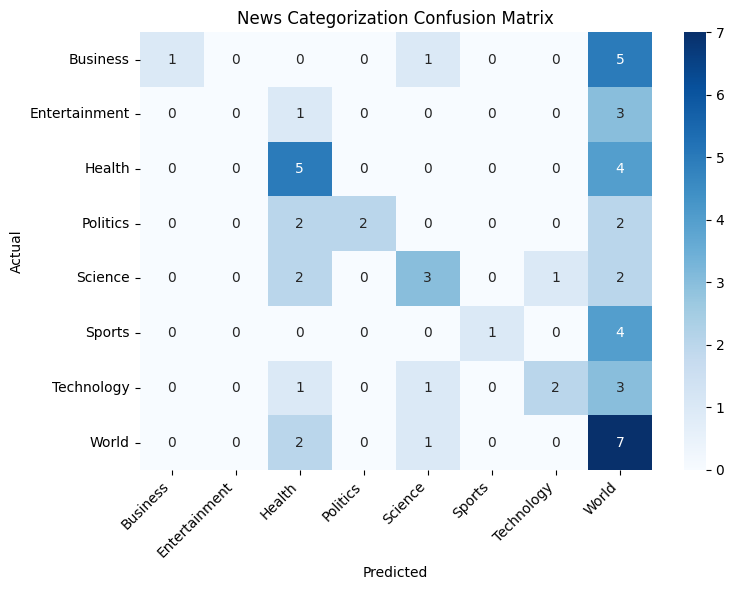

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use the 8 categories from your current pipeline
labels = model_pipeline.classes_
cm = confusion_matrix(y_test, preds, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("News Categorization Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
def predict_news(article_text):
    category = model_pipeline.predict([article_text])[0]
    probs = model_pipeline.predict_proba([article_text])[0]
    confidence = max(probs) * 100
    print(f"Category: {category} ({confidence:.1f}% confidence)")

predict_news("Apple unveils new M4 chip with faster AI neural engine.")
predict_news("India wins the T20 World Cup final in a thrilling last-over finish.")

Category: Technology (22.5% confidence)
Category: Sports (17.9% confidence)
